# HC-AAL v3 — Three-Model Committee (Kaggle)
**Dataset:** [JohnSmith Heart Disease Dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)

**Exactly three committee members, all different from the paper's XGBoost, Random Forest and Logistic Regression:**
1. K-Nearest Neighbors (KNN)
2. Gaussian Naive Bayes (GNB)
3. Multi-Layer Perceptron (MLP)

The notebook retains the HC-AAL structure: paper-inspired positive-class CW-QBC disagreement, K-Means diversity selection, adaptive query size (3 → 4 → 5), and pool-based active learning. This is a new model-committee variant, not an exact reproduction of the paper.

## 1. Kaggle setup
In Kaggle, create a notebook and click **Add Input** → attach `johnsmith88/heart-disease-dataset`. No core packages are upgraded.

In [5]:
import os, glob, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
print("NumPy:", np.__version__, "| Pandas:", pd.__version__)

NumPy: 2.1.3 | Pandas: 2.3.3


## 2. Load dataset

In [6]:
paths = [
    "/kaggle/input/heart-disease-dataset/heart.csv",
    "/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv"
]
csv_path = next((p for p in paths if os.path.exists(p)), None)
if csv_path is None:
    found = glob.glob("/kaggle/input/**/heart.csv", recursive=True)
    if not found:
        raise FileNotFoundError("Attach johnsmith88/heart-disease-dataset using Kaggle Add Input.")
    csv_path = found[0]

df = pd.read_csv(csv_path)
df.columns = [str(c).strip().lower() for c in df.columns]
assert "target" in df.columns, f"Expected 'target'; found {df.columns.tolist()}"
print("Loaded:", csv_path, "| Shape:", df.shape)
display(df.head())
print("\nTarget counts:\n", df["target"].value_counts(dropna=False))
print("\nMissing values:\n", df.isna().sum())

Loaded: /kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv | Shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Target counts:
 target
1    526
0    499
Name: count, dtype: int64

Missing values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


## 3. Prepare features and target
The commonly distributed file has 13 predictors and a binary `target`. The notebook maps the two observed target values to 0 and 1 in sorted order. **Inspect the mapping and class counts** before interpreting Class 1 as disease presence.

In [7]:
df = df.dropna(subset=["target"]).copy()
feature_cols = [c for c in df.columns if c != "target"]
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

X = df[feature_cols].copy()
raw_classes = sorted(df["target"].unique().tolist())
target_mapping = {raw_classes[0]: 0, raw_classes[1]: 1}
y = df["target"].map(target_mapping).astype(int)

print("Raw target -> encoded target:", target_mapping)
print("Encoded counts:\n", y.value_counts().sort_index())
print("Predictor count:", X.shape[1], "| Rows:", len(X))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate predictor rows:", int(X.duplicated().sum()))
assert X.shape[1] == 13, f"Expected 13 predictors, found {X.shape[1]}"

X_train_df, X_test_df, y_train_s, y_test_s = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
# Median imputation is learned from training data only.
medians = X_train_df.median(numeric_only=True)
X_train = X_train_df.fillna(medians).reset_index(drop=True)
X_test = X_test_df.fillna(medians).reset_index(drop=True)
y_train = y_train_s.reset_index(drop=True).to_numpy(dtype=int)
y_test = y_test_s.reset_index(drop=True).to_numpy(dtype=int)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Raw target -> encoded target: {0: 0, 1: 1}
Encoded counts:
 target
0    499
1    526
Name: count, dtype: int64
Predictor count: 13 | Rows: 1025
Exact duplicate rows: 723
Duplicate predictor rows: 723
Train: (820, 13) | Test: (205, 13)


## 4. Three-model heterogeneous committee
KNN and MLP benefit from standardization. GaussianNB is also placed in a pipeline for consistent preprocessing. Each model exposes class probabilities.

In [8]:
def build_committee(seed=RANDOM_STATE):
    committee = {
        "KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=7, weights="distance"))
        ]),
        "GaussianNB": Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB(var_smoothing=1e-9))
        ]),
        "MLP": Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPClassifier(
                hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                alpha=1e-3, learning_rate_init=1e-3, max_iter=500,
                early_stopping=True, validation_fraction=0.15,
                n_iter_no_change=20, random_state=seed
            ))
        ])
    }
    assert len(committee) == 3
    return committee

def fit_committee(X_labelled, y_labelled, seed=RANDOM_STATE):
    models = build_committee(seed)
    for model in models.values():
        model.fit(X_labelled, y_labelled)
    return models

def positive_probability(model, X_data):
    pos_idx = int(np.where(model.classes_ == 1)[0][0])
    return model.predict_proba(X_data)[:, pos_idx]

def committee_probabilities(models, X_data):
    return np.column_stack([positive_probability(m, X_data) for m in models.values()])

print("Committee:", list(build_committee().keys()))

Committee: ['KNN', 'GaussianNB', 'MLP']


## 5. CW-QBC disagreement
For member positive-class probabilities \(p_m(x_i)\), and their mean \(\bar p(x_i)\), use the positive-class-only score:

\[
s(x_i)=\sum_{m=1}^{3}p_m(x_i)\log\frac{p_m(x_i)+\epsilon}{\bar p(x_i)+\epsilon}
\]

This follows the paper-inspired implementation convention used in the earlier notebook; it is not the conventional full two-class KL disagreement.

In [9]:
def cw_qbc_scores(prob_matrix, eps=1e-10):
    mean_p = prob_matrix.mean(axis=1, keepdims=True)
    return np.sum(prob_matrix * np.log((prob_matrix + eps) / (mean_p + eps)), axis=1)

## 6. K-Means diversity selection
Select the top `2*q` uncertain pool samples, cluster them into `q` groups, and choose the sample nearest each centroid.

In [10]:
def select_by_uncertainty_diversity(X_pool, scores, q, seed):
    n = len(X_pool)
    if n == 0:
        return np.array([], dtype=int)
    q = min(int(q), n)
    candidate_n = min(n, 2*q)
    candidates = np.argsort(scores)[-candidate_n:]
    if q == 1:
        return np.array([candidates[np.argmax(scores[candidates])]])

    Z = StandardScaler().fit_transform(X_pool.iloc[candidates].to_numpy(dtype=float))
    km = KMeans(n_clusters=q, random_state=seed, n_init=10)
    labels = km.fit_predict(Z)
    selected = []
    for cluster in range(q):
        members = np.where(labels == cluster)[0]
        if len(members):
            d = np.linalg.norm(Z[members] - km.cluster_centers_[cluster], axis=1)
            selected.append(int(candidates[members[np.argmin(d)]]))
    for idx in candidates[np.argsort(scores[candidates])[::-1]]:
        if len(selected) >= q:
            break
        if int(idx) not in selected:
            selected.append(int(idx))
    return np.asarray(selected[:q], dtype=int)

## 7. Active-learning loop
Initial labelled fraction is 1.5% (stratified). Query size cycles through 3, 4, 5. The test set is never used to choose samples or train the committee.

In [11]:
def initial_labelled_indices(y_values, fraction=0.015, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    chosen = []
    for cls in np.unique(y_values):
        ids = np.where(y_values == cls)[0]
        n_take = min(len(ids), max(1, int(np.ceil(len(ids) * fraction))))
        chosen.extend(rng.choice(ids, size=n_take, replace=False).tolist())
    return np.array(sorted(chosen), dtype=int)

def evaluate_committee(models, X_eval, y_eval):
    probs = committee_probabilities(models, X_eval).mean(axis=1)
    pred = (probs >= 0.5).astype(int)
    metrics = {
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, probs)
    }
    return metrics, probs, pred

def run_hcaal(X_train, y_train, X_test, y_test, seed=RANDOM_STATE,
              initial_fraction=0.015, query_sizes=(3,4,5),
              max_iterations=78, max_labelled_fraction=0.319):
    labelled = np.zeros(len(X_train), dtype=bool)
    labelled[initial_labelled_indices(y_train, initial_fraction, seed)] = True
    history, query_log = [], []
    iteration = 0

    while iteration < max_iterations and labelled.mean() < max_labelled_fraction:
        labelled_ids = np.flatnonzero(labelled)
        pool_ids = np.flatnonzero(~labelled)
        if len(pool_ids) == 0:
            break

        models = fit_committee(X_train.iloc[labelled_ids], y_train[labelled_ids], seed + iteration)
        pool_probs = committee_probabilities(models, X_train.iloc[pool_ids])
        scores = cw_qbc_scores(pool_probs)

        q = query_sizes[iteration % len(query_sizes)]
        local_ids = select_by_uncertainty_diversity(
            X_train.iloc[pool_ids].reset_index(drop=True), scores, q, seed + iteration
        )
        newly_labelled = pool_ids[local_ids]
        if len(newly_labelled) == 0:
            break
        labelled[newly_labelled] = True

        labelled_ids = np.flatnonzero(labelled)
        final_iter_models = fit_committee(
            X_train.iloc[labelled_ids], y_train[labelled_ids], seed + iteration + 10000
        )
        metrics, _, _ = evaluate_committee(final_iter_models, X_test, y_test)
        history.append({
            "iteration": iteration + 1,
            "labelled_count": len(labelled_ids),
            "labelled_fraction": labelled.mean(),
            **metrics
        })
        query_log.append({
            "iteration": iteration + 1,
            "query_size_requested": q,
            "samples_added": len(newly_labelled),
            "labelled_count": len(labelled_ids),
            "labelled_fraction": labelled.mean()
        })
        iteration += 1

    final_ids = np.flatnonzero(labelled)
    final_models = fit_committee(
        X_train.iloc[final_ids], y_train[final_ids], seed + 99999
    )
    metrics, probs, pred = evaluate_committee(final_models, X_test, y_test)
    return {
        "labelled_indices": final_ids, "committee": final_models,
        "history": pd.DataFrame(history), "query_log": pd.DataFrame(query_log),
        "metrics": metrics, "mean_probability": probs, "predictions": pred,
        "seed": seed
    }

print("HC-AAL loop ready.")

HC-AAL loop ready.


## 8. Run experiments
Use 5 runs initially. For research reporting, increase to at least 10 and report mean ± standard deviation.

In [12]:
N_RUNS = 10
run_outputs = []
for run_id in range(N_RUNS):
    print(f"Run {run_id+1}/{N_RUNS}")
    run_outputs.append(run_hcaal(
        X_train, y_train, X_test, y_test, seed=RANDOM_STATE + run_id
    ))

metrics_table = pd.DataFrame([
    {"run": i+1, **r["metrics"],
     "labelled_samples": len(r["labelled_indices"]),
     "labelled_fraction": len(r["labelled_indices"]) / len(X_train)}
    for i, r in enumerate(run_outputs)
])
display(metrics_table)
display(pd.DataFrame({
    "mean": metrics_table.drop(columns="run").mean(),
    "std": metrics_table.drop(columns="run").std()
}))

Run 1/10
Run 2/10
Run 3/10
Run 4/10
Run 5/10
Run 6/10
Run 7/10
Run 8/10
Run 9/10
Run 10/10


,run,accuracy,precision,recall,f1,roc_auc,labelled_samples,labelled_fraction
0,1,0.824390,0.780488,0.914286,0.842105,0.911714,265,0.323171
1,2,0.853659,0.831858,0.895238,0.862385,0.937333,265,0.323171
2,3,0.848780,0.885417,0.809524,0.845771,0.913619,265,0.323171
3,4,0.863415,0.853211,0.885714,0.869159,0.954667,265,0.323171
4,5,0.873171,0.837607,0.933333,0.882883,0.945429,265,0.323171
5,6,0.843902,0.817391,0.895238,0.854545,0.916000,265,0.323171
6,7,0.848780,0.842593,0.866667,0.854460,0.942190,265,0.323171
7,8,0.809756,0.800000,0.838095,0.818605,0.894000,265,0.323171
8,9,0.868293,0.914894,0.819048,0.864322,0.940095,265,0.323171
9,10,0.902439,0.889908,0.923810,0.906542,0.960667,265,0.323171


,mean,std
accuracy,0.853659,0.025812
precision,0.845337,0.041878
recall,0.878095,0.043482
f1,0.860078,0.023792
roc_auc,0.931571,0.021503
labelled_samples,265.000000,0.000000
labelled_fraction,0.323171,0.000000


## 9. Run 1 evaluation: confusion matrix, ROC curve, classification report

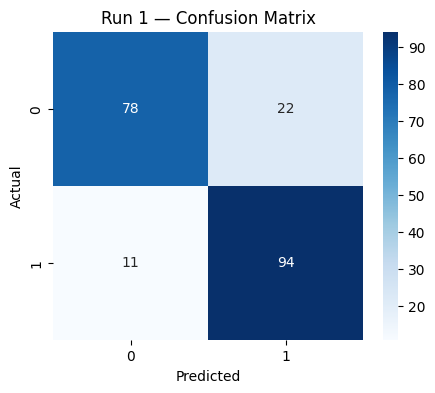

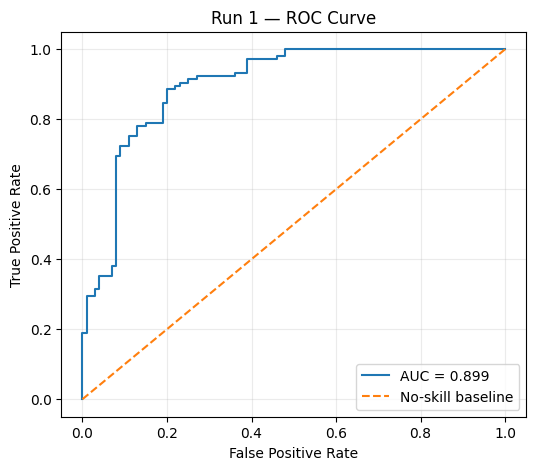

              precision    recall  f1-score   support

     Class 0       0.88      0.78      0.83       100
     Class 1       0.81      0.90      0.85       105

    accuracy                           0.84       205
   macro avg       0.84      0.84      0.84       205
weighted avg       0.84      0.84      0.84       205

Metrics: {'accuracy': 0.8390243902439024, 'precision': 0.8103448275862069, 'recall': 0.8952380952380953, 'f1': 0.8506787330316742, 'roc_auc': np.float64(0.8993333333333333)}


In [13]:
sample = run_outputs[0]
final_ids = sample["labelled_indices"]

# Use .iloc for row positions (avoids the DataFrame integer-column KeyError).
final_models = fit_committee(
    X_train.iloc[final_ids], y_train[final_ids], sample["seed"] + 999
)
metrics_out, mean_prob, predictions = evaluate_committee(final_models, X_test, y_test)

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Run 1 — Confusion Matrix"); plt.show()

fpr, tpr, _ = roc_curve(y_test, mean_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, mean_prob):.3f}")
plt.plot([0,1], [0,1], "--", label="No-skill baseline")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Run 1 — ROC Curve"); plt.legend(); plt.grid(alpha=.25); plt.show()

print(classification_report(y_test, predictions, target_names=["Class 0", "Class 1"], zero_division=0))
print("Metrics:", metrics_out)

## 10. Active-learning progress

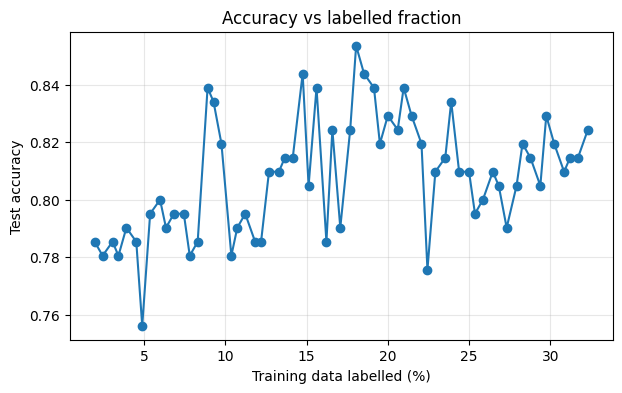

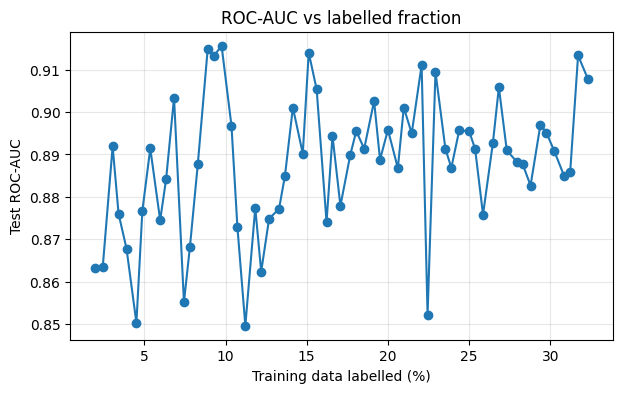

,iteration,query_size_requested,samples_added,labelled_count,labelled_fraction
0,1,3,3,16,0.019512
1,2,4,4,20,0.024390
2,3,5,5,25,0.030488
3,4,3,3,28,0.034146
4,5,4,4,32,0.039024
...,...,...,...,...,...
58,59,4,4,248,0.302439
59,60,5,5,253,0.308537
60,61,3,3,256,0.312195
61,62,4,4,260,0.317073


In [14]:
history = sample["history"]
if not history.empty:
    plt.figure(figsize=(7,4))
    plt.plot(history["labelled_fraction"]*100, history["accuracy"], marker="o")
    plt.xlabel("Training data labelled (%)"); plt.ylabel("Test accuracy")
    plt.title("Accuracy vs labelled fraction"); plt.grid(alpha=.3); plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(history["labelled_fraction"]*100, history["roc_auc"], marker="o")
    plt.xlabel("Training data labelled (%)"); plt.ylabel("Test ROC-AUC")
    plt.title("ROC-AUC vs labelled fraction"); plt.grid(alpha=.3); plt.show()

display(sample["query_log"])

## 11. Save outputs

In [15]:
OUTPUT_DIR = Path("/kaggle/working/hcaal_v3_three_model_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
metrics_table.to_csv(OUTPUT_DIR / "run_metrics.csv", index=False)

for i, result in enumerate(run_outputs, start=1):
    result["history"].to_csv(OUTPUT_DIR / f"run_{i}_history.csv", index=False)
    result["query_log"].to_csv(OUTPUT_DIR / f"run_{i}_query_log.csv", index=False)

pd.DataFrame({
    "actual": y_test,
    "predicted": sample["predictions"],
    "mean_positive_probability": sample["mean_probability"]
}).to_csv(OUTPUT_DIR / "run_1_test_predictions.csv", index=False)

print("Saved:", OUTPUT_DIR)
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved: /kaggle/working/hcaal_v3_three_model_artifacts
['run_10_history.csv', 'run_10_query_log.csv', 'run_1_history.csv', 'run_1_query_log.csv', 'run_1_test_predictions.csv', 'run_2_history.csv', 'run_2_query_log.csv', 'run_3_history.csv', 'run_3_query_log.csv', 'run_4_history.csv', 'run_4_query_log.csv', 'run_5_history.csv', 'run_5_query_log.csv', 'run_6_history.csv', 'run_6_query_log.csv', 'run_7_history.csv', 'run_7_query_log.csv', 'run_8_history.csv', 'run_8_query_log.csv', 'run_9_history.csv', 'run_9_query_log.csv', 'run_metrics.csv']


## 12. Research notes and limitations
- Committee contains **exactly KNN, GaussianNB, and MLP**; no paper committee models are used.
- The CW-QBC score is positive-class-only, as documented above.
- Duplicate rows are reported, not removed. Random splitting may put duplicate/near-duplicate records in both partitions and inflate scores.
- A Kaggle discussion has raised concerns about repeated records and target-label orientation in this dataset family. Verify the raw target mapping against the dataset's documentation before calling Class 1 “disease present”.
- This is an academic experiment, not a clinical diagnostic system.

## 13. Aggregate learning curve across runs
This plot combines the per-iteration test accuracies from all experiment runs and shows the mean ± standard deviation at each labelled-data fraction.

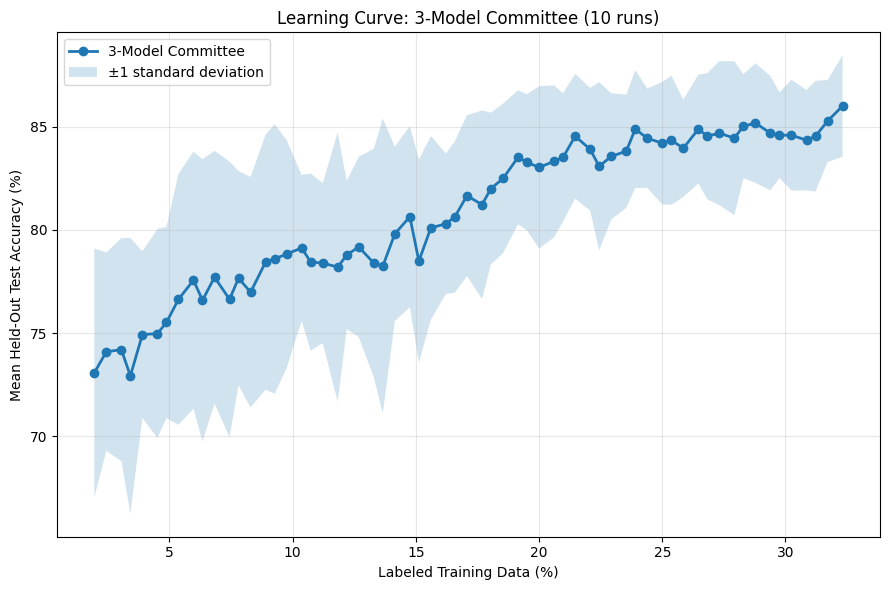

Learning curve saved to: /kaggle/working/hcaal_v3_three_model_artifacts/learning_curve_3model.png


In [16]:
# Combine the learning histories from all runs.
# Each run_outputs entry contains its own "history" DataFrame.
histories = pd.concat(
    [
        result["history"].assign(run=run_id + 1)
        for run_id, result in enumerate(run_outputs)
        if not result["history"].empty
    ],
    ignore_index=True
)

if histories.empty:
    print("No learning-history data is available to plot.")
else:
    # Calculate mean and standard deviation across runs at each labelled fraction.
    curve = (
        histories.groupby("labelled_fraction")["accuracy"]
        .agg(["mean", "std"])
        .reset_index()
        .sort_values("labelled_fraction")
    )

    plt.figure(figsize=(9, 6))

    plt.plot(
        curve["labelled_fraction"] * 100,
        curve["mean"] * 100,
        marker="o",
        linewidth=2,
        label="3-Model Committee"
    )

    # std can be NaN if a labelled fraction appears in only one run.
    lower = (curve["mean"] - curve["std"].fillna(0)) * 100
    upper = (curve["mean"] + curve["std"].fillna(0)) * 100
    plt.fill_between(
        curve["labelled_fraction"] * 100,
        lower,
        upper,
        alpha=0.2,
        label="±1 standard deviation"
    )

    plt.xlabel("Labeled Training Data (%)")
    plt.ylabel("Mean Held-Out Test Accuracy (%)")
    plt.title(f"Learning Curve: 3-Model Committee ({len(run_outputs)} runs)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plot_path = OUTPUT_DIR / "learning_curve_3model.png"
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Learning curve saved to: {plot_path}")

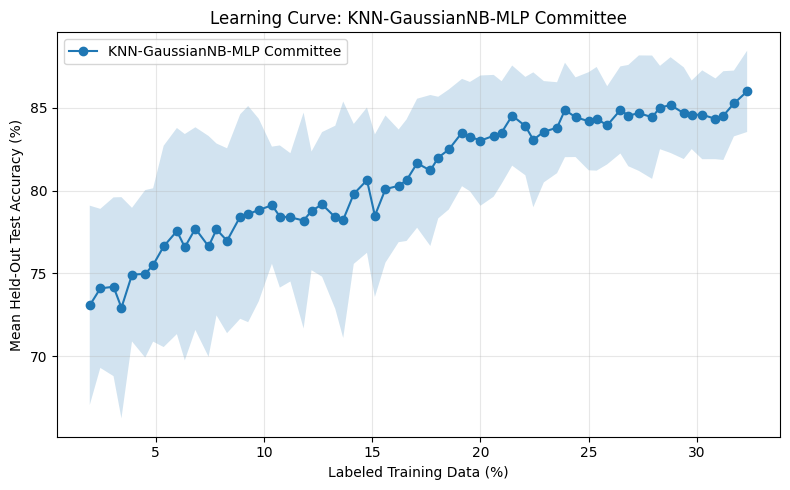

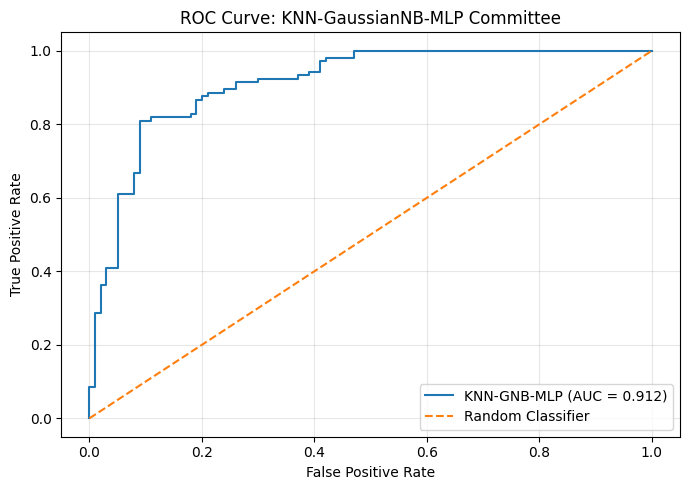

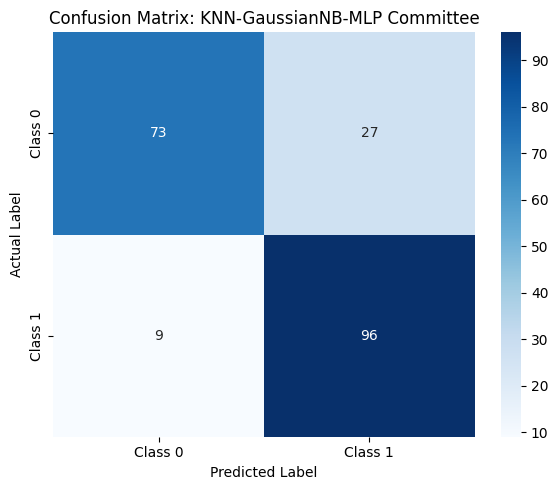


All graphs saved successfully!
knn_gnb_mlp_learning_curve.png -> /kaggle/working/hcaal_v3_three_model_artifacts/knn_gnb_mlp_learning_curve.png
knn_gnb_mlp_confusion_matrix.png -> /kaggle/working/hcaal_v3_three_model_artifacts/knn_gnb_mlp_confusion_matrix.png
knn_gnb_mlp_roc_curve.png -> /kaggle/working/hcaal_v3_three_model_artifacts/knn_gnb_mlp_roc_curve.png


In [17]:
# ==========================================
# SAVE GRAPHS: KNN + GaussianNB + MLP
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# Output directory
OUTPUT_DIR = Path("/kaggle/working/hcaal_v3_three_model_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the results already generated by the notebook
sample = run_outputs[0]

# ------------------------------------------
# 1. LEARNING CURVE
# Mean accuracy across all five runs
# ------------------------------------------

histories = []

for run_id, result in enumerate(run_outputs, start=1):
    h = result["history"].copy()
    h["run"] = run_id
    histories.append(h)

all_histories = pd.concat(histories, ignore_index=True)

learning_curve = (
    all_histories.groupby("iteration")
    .agg(
        labelled_fraction=("labelled_fraction", "mean"),
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std")
    )
    .reset_index()
)

x = learning_curve["labelled_fraction"] * 100
mean_acc = learning_curve["mean_accuracy"] * 100
std_acc = learning_curve["std_accuracy"].fillna(0) * 100

plt.figure(figsize=(8, 5))

plt.plot(
    x, mean_acc,
    marker="o",
    label="KNN-GaussianNB-MLP Committee"
)

plt.fill_between(
    x,
    mean_acc - std_acc,
    mean_acc + std_acc,
    alpha=0.2
)

plt.xlabel("Labeled Training Data (%)")
plt.ylabel("Mean Held-Out Test Accuracy (%)")
plt.title("Learning Curve: KNN-GaussianNB-MLP Committee")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "knn_gnb_mlp_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------
# 2. ROC CURVE
# Representative run: Run 1
# ------------------------------------------

y_true = y_test
y_prob = sample["mean_probability"]

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
auc = roc_auc_score(y_true, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"KNN-GNB-MLP (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve: KNN-GaussianNB-MLP Committee")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "knn_gnb_mlp_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------
# 3. CONFUSION MATRIX
# Representative run: Run 1
# ------------------------------------------

y_pred = sample["predictions"]

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix: KNN-GaussianNB-MLP Committee")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "knn_gnb_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()


# ------------------------------------------
# 4. CONFIRM SAVED FILES
# ------------------------------------------

print("\nAll graphs saved successfully!")

for file in OUTPUT_DIR.glob("knn_gnb_mlp_*.png"):
    print(file.name, "->", file)